# 02. CNN Baseline Training — ResNet18

## Goal

Train a reproducible five-class CNN baseline using **PlantVillage training images only**, and select the best checkpoint based on **validation macro-F1**.

**Experimental protocol**

- Source domain: PlantVillage (Lab)
- Training: `lab_train.csv`
- Model selection: `lab_val.csv`
- Final laboratory test: `lab_test.csv` (reserved for later evaluation)
- Cross-domain field test: `field_test.csv` (reserved for later evaluation)
- The PlantDoc training partition is not used in this baseline.

**Baseline settings**: ImageNet-pretrained ResNet18, 224 × 224 images, batch size 32, two-stage fine-tuning, no stochastic data augmentation. The augmentation experiments will be conducted separately.

## 1. Connect to Google Colab and check the GPU

In [1]:
%pip install -q datasets pandas scikit-learn matplotlib pillow

import sys
import torch
import torchvision

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "Select a GPU runtime before training."
print("GPU:", torch.cuda.get_device_name(0))

Python: 3.12.13
PyTorch: 2.10.0+cu128
TorchVision: 0.25.0+cu128
CUDA available: True
GPU: Tesla T4


## 2. Synchronize the GitHub repository

In [2]:
from pathlib import Path
import subprocess
import sys

REPO_URL = "https://github.com/thutrang147/plant-disease-diagnosis.git"
PROJECT_ROOT = Path("/content/plant-disease-diagnosis")

if not PROJECT_ROOT.exists():
    if "YOUR_USERNAME" in REPO_URL:
        raise ValueError("Replace YOUR_USERNAME with the GitHub owner shown by git remote get-url origin.")
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_ROOT)], check=True)
else:
    subprocess.run(["git", "-C", str(PROJECT_ROOT), "pull", "--ff-only"], check=True)

sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)
print("Git revision:", subprocess.check_output(
    ["git", "-C", str(PROJECT_ROOT), "rev-parse", "--short", "HEAD"], text=True
).strip())

Project root: /content/plant-disease-diagnosis
Git revision: a1fb3f7


## 3. Configure experiments and persistent output storage

Google Colab runtime storage is temporary. Save trained checkpoints and experiment results in Google Drive so they persist after the runtime disconnects.

In [3]:
from google.colab import drive
from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from torch import nn
from torch.utils.data import DataLoader
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

from src.dataset import PlantDiseaseDataset

drive.mount("/content/drive")

SEED = 42
BATCH_SIZE = 32
HEAD_EPOCHS = 3
FINETUNE_EPOCHS = 5
NUM_WORKERS = 0  # Robust starting point for Hugging Face image datasets

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda")

SPLITS_DIR = PROJECT_ROOT / "data" / "splits"
if not SPLITS_DIR.exists():
    legacy_dir = PROJECT_ROOT / "splits"
    if legacy_dir.exists():
        SPLITS_DIR = legacy_dir
        print("WARNING: Using legacy splits/ directory. Prefer data/splits/ in the repository.")
    else:
        raise FileNotFoundError("Missing data/splits/ (or splits/). Push the manifests from your Mac first.")

RESULTS_DIR = Path("/content/drive/MyDrive/plant-disease-diagnosis/resnet18_baseline")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

label_map = json.loads((SPLITS_DIR / "label_map.json").read_text(encoding="utf-8"))
CLASS_NAMES = [name for name, idx in sorted(label_map.items(), key=lambda kv: kv[1])]
assert len(CLASS_NAMES) == 5 and sorted(label_map.values()) == list(range(5))

print("Labels:", label_map)
print("Split location:", SPLITS_DIR)
print("Result location:", RESULTS_DIR)

source_file = SPLITS_DIR / "dataset_sources.json"
if source_file.exists():
    source_info = json.loads(source_file.read_text(encoding="utf-8"))
    print("Dataset source configuration:", source_info)
    print("NOTE: Pin PlantVillage to a fixed commit SHA before reporting final research results.")

Mounted at /content/drive
Labels: {'Healthy': 0, 'Early Blight': 1, 'Late Blight': 2, 'Bacterial Spot': 3, 'Septoria Leaf Spot': 4}
Split location: /content/plant-disease-diagnosis/data/splits
Result location: /content/drive/MyDrive/plant-disease-diagnosis/resnet18_baseline
Dataset source configuration: {'plantvillage': {'repository': 'geraldmc/plantvillage-full', 'requested_revision': 'default'}, 'plantdoc': {'repository': 'geraldmc/plantdoc-full', 'requested_revision': 'v0.1.0'}, 'seed': 42, 'validation_strategy': 'StratifiedGroupKFold: selected fold closest to 20% of original PlantVillage Train', 'note': 'Row IDs refer to the loading order of these datasets. Pin resolved dataset commit SHAs before a published experiment.'}
NOTE: Pin PlantVillage to a fixed commit SHA before reporting final research results.


## 4. Load the training and validation datasets

Use the preprocessing associated with the official ImageNet ResNet18 weights for **both** partitions. No random augmentation is applied in this baseline so later augmentation experiments have a clear reference point.

Only the two laboratory manifests are used. `src/dataset.py` loads image pixels from the original Hugging Face datasets and maps them to the standardized five-class labels.

In [4]:
from torchvision.models import ResNet18_Weights

WEIGHTS = ResNet18_Weights.IMAGENET1K_V1
preprocess = WEIGHTS.transforms()

train_dataset = PlantDiseaseDataset(
    SPLITS_DIR / "lab_train.csv", transform=preprocess
)
val_dataset = PlantDiseaseDataset(
    SPLITS_DIR / "lab_val.csv", transform=preprocess
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Preprocessing:", preprocess)

x, y = next(iter(train_loader))
print("First batch images:", tuple(x.shape))
print("First batch labels:", tuple(y.shape))
assert x.shape[1:] == (3, 224, 224)
assert y.min() >= 0 and y.max() < 5

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Train images: 5365
Validation images: 1341
Preprocessing: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
First batch images: (32, 3, 224, 224)
First batch labels: (32,)


## 5. Initialize the ResNet18 classifier

The pretrained backbone learns generic visual features. Replace the original 1,000-class head with a five-class linear layer.

**Phase 1 — linear probing:** keep the feature extractor frozen and train only the new classifier head.

**Phase 2 — fine-tuning:** unfreeze the full network and continue training with a smaller backbone learning rate.

In [5]:
model = resnet18(weights=WEIGHTS)
model.fc = nn.Linear(model.fc.in_features, len(CLASS_NAMES))
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()

# Freeze the pretrained backbone for phase 1.
for name, parameter in model.named_parameters():
    parameter.requires_grad = name.startswith("fc.")

print("Classifier:", model.fc)
print("Trainable parameters (phase 1):", sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Total parameters:", sum(p.numel() for p in model.parameters()))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 123MB/s] 


Classifier: Linear(in_features=512, out_features=5, bias=True)
Trainable parameters (phase 1): 2565
Total parameters: 11179077


## 6. Define training and validation metrics

Track mean cross-entropy loss, accuracy, and macro-F1 per epoch. The best checkpoint is selected by **validation macro-F1**. The validation set is not used to update weights.

The batch normalization statistics are kept fixed during the classifier-only stage.

In [6]:
from sklearn.metrics import f1_score, accuracy_score


def run_epoch(model, loader, optimizer=None, freeze_backbone=False):
    is_training = optimizer is not None
    model.train(is_training)

    if is_training and freeze_backbone:
        # Keep pretrained BatchNorm running statistics fixed in phase 1.
        for module in model.modules():
            if isinstance(module, nn.modules.batchnorm._BatchNorm):
                module.eval()

    total_loss = 0.0
    all_true = []
    all_pred = []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            logits = model(images)
            loss = criterion(logits, labels)
            if is_training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * len(labels)
        all_true.extend(labels.detach().cpu().tolist())
        all_pred.extend(logits.argmax(dim=1).detach().cpu().tolist())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_true, all_pred),
        "macro_f1": f1_score(
            all_true, all_pred, labels=list(range(len(CLASS_NAMES))),
            average="macro", zero_division=0
        ),
    }


history = []
best_f1 = -1.0
CHECKPOINT = RESULTS_DIR / "resnet18_lab_best.pt"


def train_phase(phase_name, n_epochs, optimizer, freeze_backbone):
    global best_f1

    for epoch in range(1, n_epochs + 1):
        train_metrics = run_epoch(
            model, train_loader, optimizer=optimizer,
            freeze_backbone=freeze_backbone
        )
        val_metrics = run_epoch(model, val_loader)

        record = {
            "phase": phase_name,
            "epoch_in_phase": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "train_macro_f1": train_metrics["macro_f1"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
        }
        history.append(record)
        pd.DataFrame(history).to_csv(RESULTS_DIR / "training_history.csv", index=False)

        if val_metrics["macro_f1"] > best_f1:
            best_f1 = val_metrics["macro_f1"]
            torch.save({
                "model_state_dict": model.state_dict(),
                "class_names": CLASS_NAMES,
                "architecture": "resnet18",
                "pretrained_weights": "IMAGENET1K_V1",
                "best_val_macro_f1": best_f1,
                "phase": phase_name,
                "epoch_in_phase": epoch,
                "seed": SEED,
            }, CHECKPOINT)

        print(
            f"{phase_name} | {epoch}/{n_epochs} | "
            f"train loss={train_metrics['loss']:.4f}, f1={train_metrics['macro_f1']:.4f} | "
            f"val loss={val_metrics['loss']:.4f}, "
            f"acc={val_metrics['accuracy']:.4f}, f1={val_metrics['macro_f1']:.4f} | "
            f"best f1={best_f1:.4f}"
        )

## 7. Train Phase 1 — Classifier head

Freeze the pretrained backbone and optimize only the replacement classification head.

In [7]:
head_optimizer = torch.optim.AdamW(
    model.fc.parameters(), lr=1e-3, weight_decay=1e-4
)
train_phase(
    "classifier_head", HEAD_EPOCHS,
    optimizer=head_optimizer, freeze_backbone=True
)

classifier_head | 1/3 | train loss=0.6934, f1=0.7406 | val loss=0.4326, acc=0.8740, f1=0.8458 | best f1=0.8458
classifier_head | 2/3 | train loss=0.3438, f1=0.8806 | val loss=0.3243, acc=0.9001, f1=0.8786 | best f1=0.8786
classifier_head | 3/3 | train loss=0.2657, f1=0.9069 | val loss=0.2830, acc=0.9098, f1=0.8929 | best f1=0.8929


## 8. Train Phase 2 — Fine-tune the full CNN

Unfreeze the backbone. Use a lower learning rate for pretrained layers than for the newly initialized classifier head.

In [8]:
for parameter in model.parameters():
    parameter.requires_grad = True

finetune_optimizer = torch.optim.AdamW(
    [
        {"params": [p for n, p in model.named_parameters() if not n.startswith("fc.")], "lr": 1e-4},
        {"params": model.fc.parameters(), "lr": 5e-4},
    ],
    weight_decay=1e-4,
)
train_phase(
    "full_finetune", FINETUNE_EPOCHS,
    optimizer=finetune_optimizer, freeze_backbone=False
)

full_finetune | 1/5 | train loss=0.1581, f1=0.9345 | val loss=0.0820, acc=0.9732, f1=0.9667 | best f1=0.9667
full_finetune | 2/5 | train loss=0.0197, f1=0.9918 | val loss=0.0603, acc=0.9843, f1=0.9821 | best f1=0.9821
full_finetune | 3/5 | train loss=0.0178, f1=0.9944 | val loss=0.0812, acc=0.9806, f1=0.9757 | best f1=0.9821
full_finetune | 4/5 | train loss=0.0168, f1=0.9948 | val loss=0.0474, acc=0.9896, f1=0.9879 | best f1=0.9879
full_finetune | 5/5 | train loss=0.0176, f1=0.9948 | val loss=0.0566, acc=0.9851, f1=0.9833 | best f1=0.9879


## 9. Inspect training curves

Review whether validation loss and macro-F1 improve across the two training phases. A large and sustained gap between training and validation results may indicate overfitting.

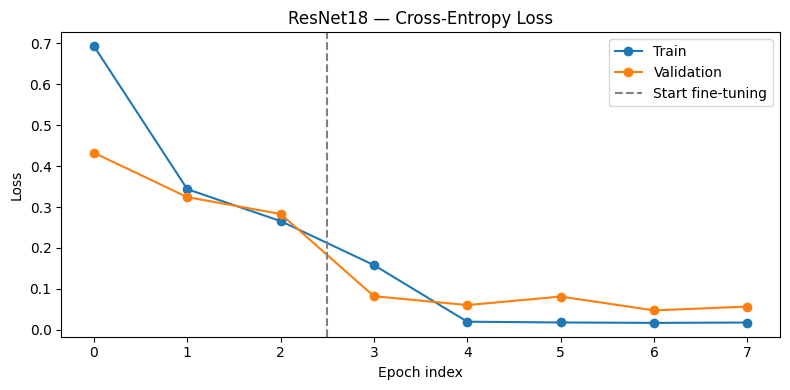

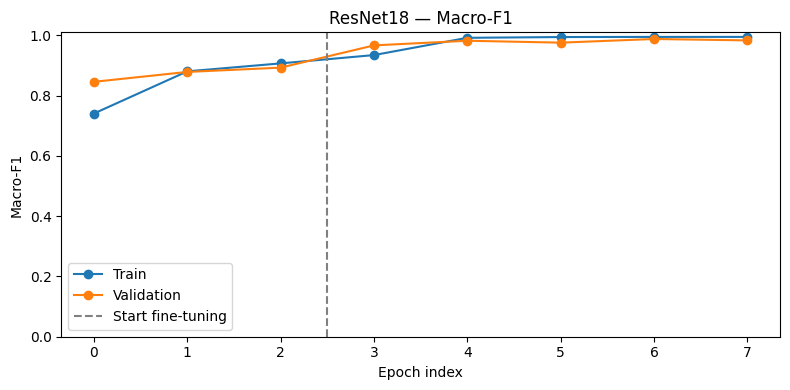

,phase,epoch_in_phase,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1
0,classifier_head,1,0.693425,0.786207,0.740627,0.432554,0.873975,0.845795
1,classifier_head,2,0.343779,0.901212,0.880557,0.324297,0.900075,0.878618
2,classifier_head,3,0.265698,0.922647,0.906931,0.283000,0.909769,0.892851
3,full_finetune,1,0.158085,0.942777,0.934531,0.082029,0.973154,0.966688
4,full_finetune,2,0.019663,0.993290,0.991848,0.060330,0.984340,0.982115
5,full_finetune,3,0.017818,0.994595,0.994351,0.081171,0.980611,0.975749
6,full_finetune,4,0.016787,0.995340,0.994813,0.047376,0.989560,0.987887
7,full_finetune,5,0.017638,0.995340,0.994824,0.056583,0.985086,0.983264


In [9]:
history_df = pd.DataFrame(history)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history_df["train_loss"], marker="o", label="Train")
ax.plot(history_df["val_loss"], marker="o", label="Validation")
ax.axvline(HEAD_EPOCHS - 0.5, linestyle="--", color="gray", label="Start fine-tuning")
ax.set(title="ResNet18 — Cross-Entropy Loss", xlabel="Epoch index", ylabel="Loss")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "loss_curve.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history_df["train_macro_f1"], marker="o", label="Train")
ax.plot(history_df["val_macro_f1"], marker="o", label="Validation")
ax.axvline(HEAD_EPOCHS - 0.5, linestyle="--", color="gray", label="Start fine-tuning")
ax.set(title="ResNet18 — Macro-F1", xlabel="Epoch index", ylabel="Macro-F1", ylim=(0, 1.01))
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "macro_f1_curve.png", dpi=160)
plt.show()

display(history_df)

## 10. Evaluate the best checkpoint on the validation partition

Reload the highest-scoring checkpoint and generate per-class precision, recall, F1, and a confusion matrix. This is **validation analysis**, not the final Lab or Field benchmark.

Best validation macro-F1: 0.9879
                    precision    recall  f1-score   support

           Healthy     0.9960    0.9921    0.9941       253
      Early Blight     0.9689    0.9750    0.9720       160
       Late Blight     0.9967    0.9837    0.9901       306
    Bacterial Spot     0.9971    0.9941    0.9956       340
Septoria Leaf Spot     0.9791    0.9965    0.9877       282

          accuracy                         0.9896      1341
         macro avg     0.9876    0.9883    0.9879      1341
      weighted avg     0.9896    0.9896    0.9896      1341



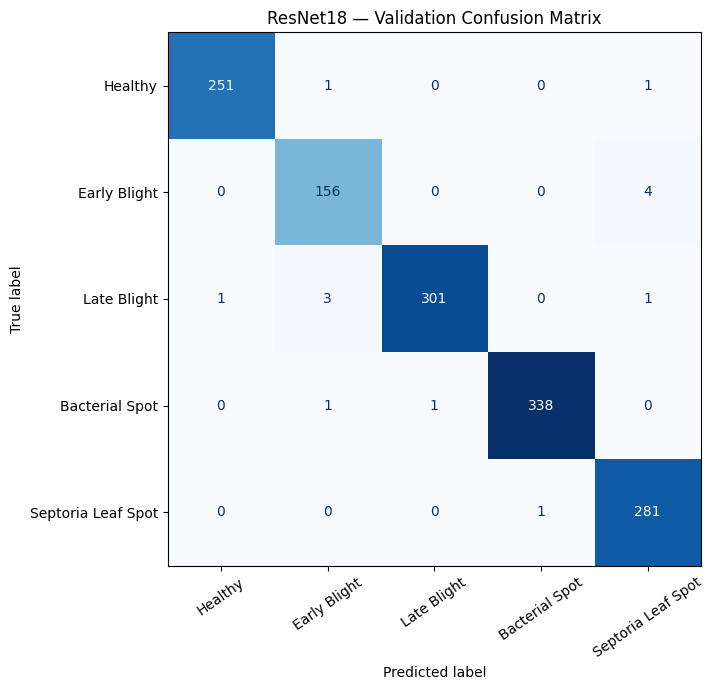

Checkpoint: /content/drive/MyDrive/plant-disease-diagnosis/resnet18_baseline/resnet18_lab_best.pt
Results: /content/drive/MyDrive/plant-disease-diagnosis/resnet18_baseline


In [10]:
checkpoint = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=True)
assert checkpoint["class_names"] == CLASS_NAMES
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

y_true, y_pred = [], []
with torch.inference_mode():
    for images, labels in val_loader:
        outputs = model(images.to(DEVICE, non_blocking=True))
        y_pred.extend(outputs.argmax(dim=1).cpu().tolist())
        y_true.extend(labels.tolist())

report = classification_report(
    y_true, y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    digits=4, zero_division=0,
)
print("Best validation macro-F1:", round(checkpoint["best_val_macro_f1"], 4))
print(report)
(RESULTS_DIR / "validation_classification_report.txt").write_text(report, encoding="utf-8")

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES))))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", colorbar=False, xticks_rotation=35
)
ax.set_title("ResNet18 — Validation Confusion Matrix")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "validation_confusion_matrix.png", dpi=160)
plt.show()

print("Checkpoint:", CHECKPOINT)
print("Results:", RESULTS_DIR)

## 11. Interpretation and next steps

After training, summarize the results using the executed values:

- Best validation macro-F1 and accuracy
- Classes with the highest and lowest recall
- Train-vs-validation gap and signs of overfitting
- Whether classifier-only training or full fine-tuning produced the best checkpoint

**Next experiment:** freeze the training protocol and evaluate the selected checkpoint on **PlantVillage Lab Test** and **PlantDoc Field Test** to measure the cross-domain performance gap. Do not use Field Test to select hyperparameters or the best checkpoint.

**Reproducibility note:** the manifest references image row IDs in upstream datasets. Record and pin the exact Hugging Face dataset revisions before treating the results as a final, reproducible research benchmark.